In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use(
    'seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default'
)
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

In [2]:
t = np.linspace(
    start = 0.0,
    stop = 2.0,
    num = 200
)
f = 2.0 # Frequency = 2 Hz
A = 3.0 # Amplitude
phi = 0.0
print(t[:5])

y_pure = A * np.sin(2 * np.pi * f * t + phi)

gaussian_noise = np.random.normal(
    loc = 0.0,
    scale = 0.6,
    size = len(t)
)
y_noisy = y_pure + gaussian_noise

print("==Harmonic Signal + Gaussian Noise")
print("Time Domain Array Length: ",len(t))
print(f"Signal Range(Pure): [{y_pure.min():.2f},{y_pure.max():.2f}]")
print(f"Signal Range(Noisy): [{y_noisy.min():.2f},{y_noisy.max():.2f}]")
print(f"Calculated Noise Variance: {np.var(a=gaussian_noise):.4f}\n")

[0.         0.01005025 0.0201005  0.03015075 0.04020101]
==Harmonic Signal + Gaussian Noise
Time Domain Array Length:  200
Signal Range(Pure): [-3.00,3.00]
Signal Range(Noisy): [-4.17,4.45]
Calculated Noise Variance: 0.3105



In [3]:
noise = np.random.normal(loc = 5, scale = 2, size = 10)
print(noise)

[ 5.71557472  6.12156905  7.16610249  7.1076041   2.24466126  3.12434992
  6.03007053  6.0275719   6.03009537 12.70546298]


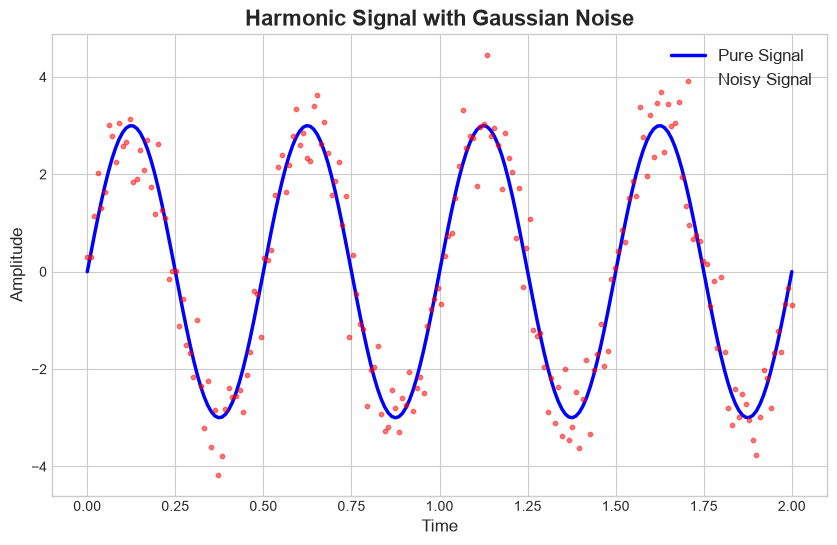

In [4]:
plt.figure(figsize = (10, 6))
plt.plot(t, 
        y_pure, 
        label = 'Pure Signal', 
        color = 'blue', 
        linewidth = 2.5,
        zorder=1
)
plt.scatter(x=t, 
            y=y_noisy, 
            label = 'Noisy Signal', 
            color = 'red', 
            zorder=1, 
            s=10, 
            alpha = 0.5
)
plt.title(label = 'Harmonic Signal with Gaussian Noise', fontsize = 16, fontweight = 'bold')
plt.xlabel('Time', fontsize = 12)
plt.ylabel('Amplitude', fontsize = 12)
plt.legend(loc = 'upper right', fontsize = 12)
plt.grid(True)

## Exponential Decay + Uniform Measurement Error

In [5]:
t_decay = np.linspace(
    start = 0.0,
    stop = 5.0,
    num = 100
)
N0 = 10.0 # Initial Amplitude
decay_rate = 0.8 # Decay constant lambda

y_decay_pure = N0 * np.exp(-decay_rate * t_decay)
print(y_decay_pure[:5])

uniform_noise = np.random.uniform(
    low = -0.5, # lower boundary of error sampling range
    high = 0.5, # Upper boundary of error sampling range
    size = len(t_decay) # Output array length matching domain grid size
)


y_decay_measured = y_decay_pure + uniform_noise

print("==Exponential Decay + Uniform Noise")
print("Time Domain Array Length: ",len(t_decay))
print(f"Initial Range(Pure): [{y_decay_pure.min():.2f}, {y_decay_pure.max():.2f}]")
print(f"Initial Range(Noisy): [{uniform_noise.min():.2f}, {uniform_noise.max():.2f}]")
print(f"Initial Range(Measured): [{y_decay_measured.min():.2f}, {y_decay_measured.max():.2f}]") 


[10.          9.6040132   9.22370695  8.85846033  8.50767699]
==Exponential Decay + Uniform Noise
Time Domain Array Length:  100
Initial Range(Pure): [0.18, 10.00]
Initial Range(Noisy): [-0.49, 0.48]
Initial Range(Measured): [-0.27, 10.30]


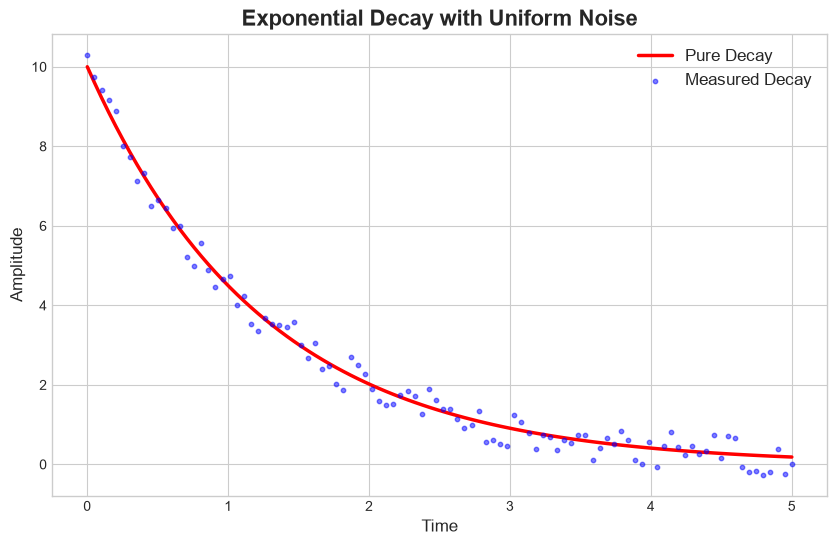

In [6]:
# Graphical Representation of Exponential Decay with Uniform Noise
plt.figure(figsize = (10, 6))
plt.plot(t_decay, 
        y_decay_pure, 
        label = 'Pure Decay', 
        color = 'red', 
        linewidth = 2.5,
        zorder=1
)
plt.scatter(x=t_decay, 
            y=y_decay_measured, 
            label = 'Measured Decay', 
            color = 'blue', 
            zorder=1, 
            s=10, 
            alpha = 0.5
)
plt.title(label = 'Exponential Decay with Uniform Noise', fontsize = 16, fontweight = 'bold')
plt.xlabel('Time', fontsize = 12)
plt.ylabel('Amplitude', fontsize = 12)
plt.legend(loc = 'upper right', fontsize = 12)
plt.grid(True)

[8.44875311 0.23271936 8.14468483 2.81854775 1.18164828 6.96737165
 6.28942847 8.77472014 7.35071044 8.0348093 ]
[-0.49739701 -0.33610862  0.44837616  0.36622216 -0.01254096  0.07039643
  0.76659894 -0.35494283  0.32825843 -0.12131559]


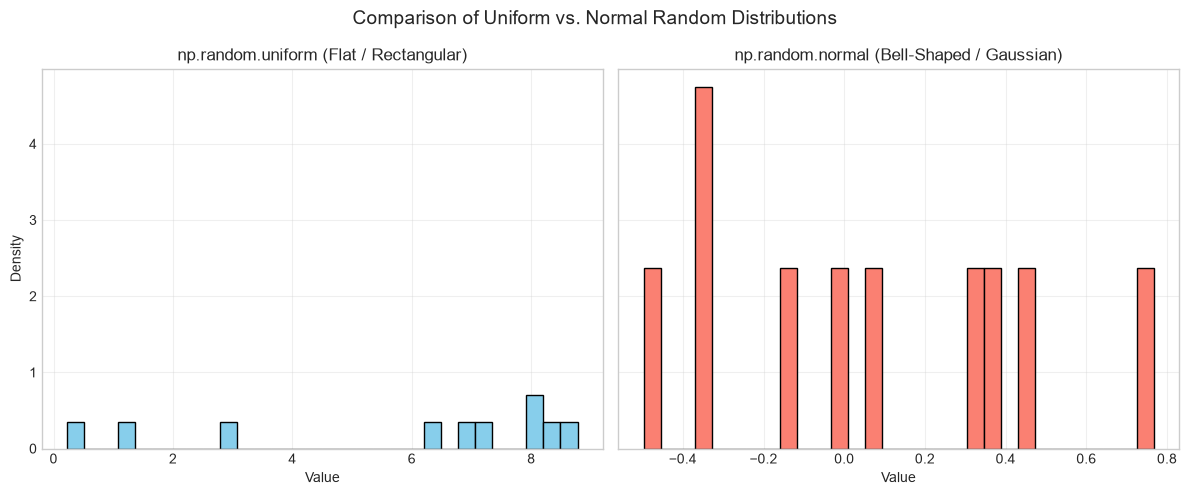

In [7]:
import numpy as np
uniform_data = np.random.uniform(low = 0.0, high=10.0, size=10)
print(uniform_data)

normal_data = np.random.normal(
    loc=0.0,      # Mean (centre) of the Gaussian distribution
    scale=0.6,    # Standard deviation (spread / noise intensity)
    size=10   # Number of random samples generated matching time array shape
)
print(normal_data)

# 2. Create a figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Plot Uniform Distribution
ax1.hist(uniform_data, bins=30, color='skyblue', edgecolor='black', density=True)
ax1.set_title('np.random.uniform (Flat / Rectangular)')
ax1.set_xlabel('Value')
ax1.set_ylabel('Density')
ax1.grid(True, alpha=0.3)

# Plot Normal Distribution
ax2.hist(normal_data, bins=30, color='salmon', edgecolor='black', density=True)
ax2.set_title('np.random.normal (Bell-Shaped / Gaussian)')
ax2.set_xlabel('Value')
ax2.grid(True, alpha=0.3)

plt.suptitle('Comparison of Uniform vs. Normal Random Distributions', fontsize=14)
plt.tight_layout()
plt.show()

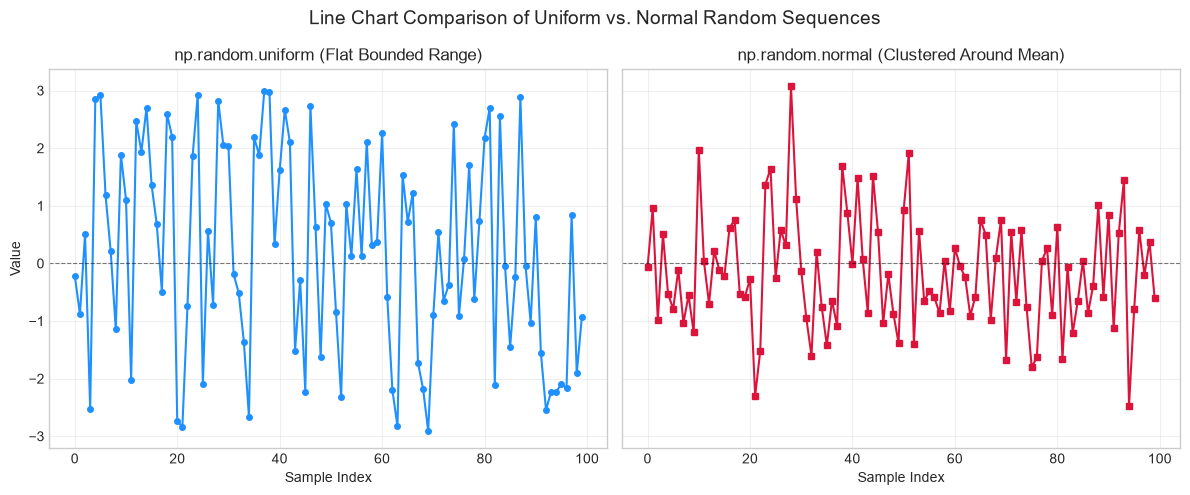

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate sequential data for both distributions (fewer points for a clean line chart)
n_points = 100
x = np.arange(n_points)

# Uniform: values spread evenly between -3 and 3
uniform_data = np.random.uniform(low=-3.0, high=3.0, size=n_points)

# Normal: values clustered around mean 0 with standard deviation 1
normal_data = np.random.normal(loc=0.0, scale=1.0, size=n_points)

# 2. Create a figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Plot Uniform Distribution Line Chart
ax1.plot(x, uniform_data, color='dodgerblue', marker='o', markersize=4, linestyle='-', linewidth=1.5)
ax1.set_title('np.random.uniform (Flat Bounded Range)')
ax1.set_xlabel('Sample Index')
ax1.set_ylabel('Value')
ax1.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax1.grid(True, alpha=0.3)

# Plot Normal Distribution Line Chart
ax2.plot(x, normal_data, color='crimson', marker='s', markersize=4, linestyle='-', linewidth=1.5)
ax2.set_title('np.random.normal (Clustered Around Mean)')
ax2.set_xlabel('Sample Index')
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
ax2.grid(True, alpha=0.3)

plt.suptitle('Line Chart Comparison of Uniform vs. Normal Random Sequences', fontsize=14)
plt.tight_layout()
plt.show()

### 3. Polynomial Function + Sparse Outliers(Salt & Pepper / Impuls Noise)

In [8]:
# ---- 1. Data Generation and Print Output----
x_poly = np.linspace(
    start = -2.0,
    stop = 2.0,
    num = 120
)

# Cubic Polynomial: p(x) = 0.5*x^3 + 1.2*x^2 + 12*x + 5
y_poly_clean = 0.5 * (x_poly**3) - (x_poly**2) - x_poly + 2.0
y_poly_corrupted = y_poly_clean.copy()
# Select 8% of indices randomly to inject impulse spiker
num_outliers = int(0.08 * len(x_poly))

outlier_indices = np.random.choice(
    a = len(x_poly),
    size = num_outliers,
    replace = False
)

# Inject random positive and negative spikes
spike_directions = np.random.choice(
    a = [-1,1],
    size = num_outliers,
    
)

spike_magnitudes = np.random.uniform(
    low = 4.0,
    high = 8.0,
    size = num_outliers
)

spikes = spike_directions * spike_magnitudes
print(spikes)
y_poly_corrupted[outlier_indices] += spikes


[-7.60463204  4.18178552 -5.12385276 -7.80164594 -7.56105514 -5.82262701
  6.48053039  5.10952473 -4.75248464]


In [9]:
print("---Ploynomial Function + Sparse Outliers---")
print("Total Data Points: ",len(x_poly))
print("Injected Outliers Count: ",len(outlier_indices))
print("Outliers Indices: ",np.array(outlier_indices))
print(f"Clean Data Mean: {np.mean(y_poly_clean):.4f} & Corrupted Data Mean: {np.mean(y_poly_corrupted):.4f}")

---Ploynomial Function + Sparse Outliers---
Total Data Points:  120
Injected Outliers Count:  9
Outliers Indices:  [ 20  55  66 103  40  80 116  90  43]
Clean Data Mean: 0.6443 & Corrupted Data Mean: 0.4535


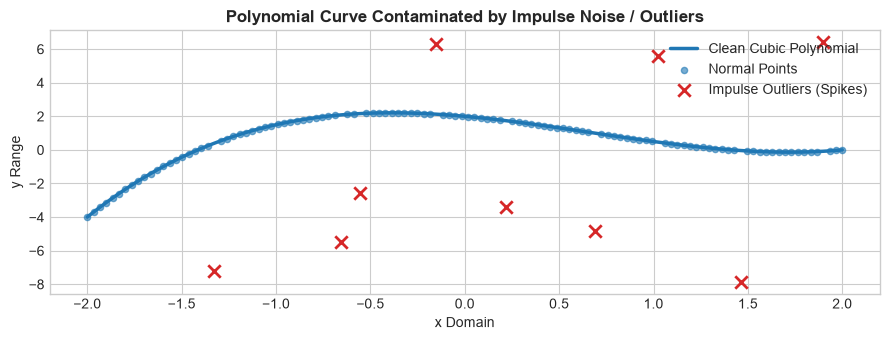

In [12]:
plt.figure(
    figsize=(9, 3.5)  # Figure dimension configuration in inches
)

# Clean polynomial curve
plt.plot(
    x_poly,                                                      # Domain coordinates
    y_poly_clean,                                                # Uncorrupted polynomial curve points
    color='#1f77b4',                                             # Dark blue line color
    linewidth=2.5,                                               # Line stroke width
    zorder=2,                                                    # Layer ordering
    label='Clean Cubic Polynomial'                               # Legend text
)

# Uncorrupted points (regular observations)
normal_mask = np.ones(
    shape=len(x_poly),                                           # Mask shape matching array size
    dtype=bool                                                   # Boolean mask data type
)
normal_mask[outlier_indices] = False
plt.scatter(
    x=x_poly[normal_mask],                                       # Domain points for clean subset
    y=y_poly_corrupted[normal_mask],                             # Corresponding clean response values
    color='#1f77b4',                                             # Blue dot marker color
    s=20,                                                        # Dot marker size
    alpha=0.6,                                                   # Marker opacity
    label='Normal Points'                                        # Legend title
)

# Outlier spikes (highlighted in red)
plt.scatter(
    x=x_poly[outlier_indices],                                   # Outlier X-coordinates
    y=y_poly_corrupted[outlier_indices],                         # Outlier corrupted Y-values
    color='#d62728',                                             # Crimson red color for immediate visual detection
    marker='x',                                                  # Cross symbol marker representation
    s=80,                                                        # Enlarged marker size
    linewidth=2,                                                 # Cross symbol line stroke width
    zorder=4,                                                    # Top visual layer priority
    label='Impulse Outliers (Spikes)'                            # Legend label
)

plt.title(
    label='Polynomial Curve Contaminated by Impulse Noise / Outliers', # Title string
    fontsize=12,                                                       # Font size
    fontweight='bold'                                                  # Bold weight
)
plt.xlabel(xlabel='x Domain')                                    # X-axis label
plt.ylabel(ylabel='y Range')                                     # Y-axis label
plt.legend(loc='upper right')                                    # Legend location
plt.tight_layout()                                               # Optimize subplot alignment
plt.show()

4. Multi-Component Composite Signal + Heteroscedastic Noise

=== 4. COMPOSITE SIGNAL + HETEROSCEDASTIC NOISE ===
Initial Noise Std Dev (t=0): 0.10
Final Noise Std Dev (t=10): 1.10
Overall Composite Signal Length: 300



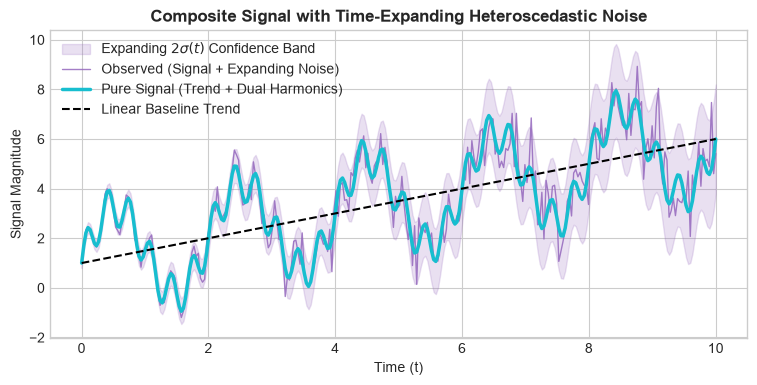

In [13]:
# --- 1. DATA GENERATION & PRINT OUTPUT ---
t_comp = np.linspace(
    start=0.0,  # Start time in seconds
    stop=10.0,  # Stop time in seconds (10 second window)
    num=300     # Evaluation step count
)

# Component 1: Linear upward trend (m=0.5, c=1.0)
trend = 0.5 * t_comp + 1.0

# Component 2 & 3: Dual-frequency harmonics (0.5 Hz low freq + 3.0 Hz high freq)
harmonics = 2.0 * np.sin(2 * np.pi * 0.5 * t_comp) + 0.8 * np.sin(2 * np.pi * 3.0 * t_comp)

S_pure = trend + harmonics

# Time-dependent standard deviation: sigma grows from 0.1 at t=0 to 1.1 at t=10
sigma_t = 0.1 + 0.1 * t_comp
hetero_noise = np.random.normal(
    loc=0.0,           # Zero mean base noise distribution
    scale=1.0,         # Standard unit normal standard deviation
    size=len(t_comp)   # Sample size matching domain array length
) * sigma_t
y_composite = S_pure + hetero_noise

print("=== 4. COMPOSITE SIGNAL + HETEROSCEDASTIC NOISE ===")
print(f"Initial Noise Std Dev (t=0): {sigma_t[0]:.2f}")
print(f"Final Noise Std Dev (t=10): {sigma_t[-1]:.2f}")
print(f"Overall Composite Signal Length: {len(y_composite)}\n")


# --- 2. GRAPHICAL VISUALIZATION ---
plt.figure(
    figsize=(9, 4)  # Width and height of canvas frame in inches
)

# Time-expanding error region visual
plt.fill_between(
    x=t_comp,                                                      # Time axis coordinates
    y1=S_pure - 2 * sigma_t,                                      # Lower 2-sigma lower envelope threshold
    y2=S_pure + 2 * sigma_t,                                      # Upper 2-sigma upper envelope threshold
    color='#9467bd',                                               # Soft purple fill color
    alpha=0.2,                                                     # Envelope translucent shading factor
    label='Expanding $2\\sigma(t)$ Confidence Band'                 # Legend label
)

# Observed composite series plot
plt.plot(
    t_comp,                                                        # Time grid
    y_composite,                                                   # Signal + heteroscedastic noise observations
    color='#9467bd',                                               # Muted purple line color
    linewidth=1.0,                                                 # Thin line for noisy signal details
    alpha=0.85,                                                    # Translucency level
    label='Observed (Signal + Expanding Noise)'                    # Legend text
)
plt.plot(
    t_comp,                                                        # Time grid
    S_pure,                                                        # Pure combined signal values
    color='#17becf',                                               # Cyan line color
    linewidth=2.5,                                                 # Line stroke thickness
    label='Pure Signal (Trend + Dual Harmonics)'                  # Legend text
)
plt.plot(
    t_comp,                                                        # Time grid
    trend,                                                         # Trend line component
    'k--',                                                         # Black dashed line format
    linewidth=1.5,                                                 # Dashed line thickness
    label='Linear Baseline Trend'                                  # Legend entry
)

plt.title(
    label='Composite Signal with Time-Expanding Heteroscedastic Noise', # Title
    fontsize=12,                                                        # Font size
    fontweight='bold'                                                   # Bold title font style
)
plt.xlabel(xlabel='Time (t)')                                       # X-axis label
plt.ylabel(ylabel='Signal Magnitude')                               # Y-axis label
plt.legend(loc='upper left')    